# Solar Thermal | Exploratory Data Analysis

This section describes the capacity factor series in `dataset/UVTgv_OD/production/Solar_Thermal.csv`. The capacity factor is expressed as a fraction. The CSV provides values in file order and contains no timestamps.

To rerun, put the CSV next to this notebook or run it from the repository root. The analysis uses pandas and matplotlib.

Source: E-LAND_datasets_readme_UVTgv.txt, Description. The solar thermal entry identifies an hourly profile for 2021. The 8,760 rows match a full non-leap year. The calendar plots assume row 0 is 2021-01-01 00:00 and that the rows are consecutive. The README does not specify the time zone or explicitly state the starting hour.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

solar_relative_path = Path("dataset/UVTgv_OD/production/Solar_Thermal.csv")
solar_candidates = [
    Path("Solar_Thermal.csv"),
    *(folder / solar_relative_path for folder in (Path.cwd(), *Path.cwd().parents)),
    Path("upload/Solar_Thermal.csv"),
]
solar_path = next((path for path in solar_candidates if path.is_file()), None)
if solar_path is None:
    raise FileNotFoundError("Place Solar_Thermal.csv beside the notebook or run inside the repository.")
solar_raw = pd.read_csv(solar_path, skip_blank_lines=False)["capacity_factor"]
solar_cf = pd.to_numeric(solar_raw, errors="coerce")
solar_valid = solar_cf.where(solar_cf.between(0, 1))

solar_checks = pd.Series({
    "Rows": len(solar_raw),
    "Missing": solar_raw.isna().sum(),
    "Nonnumeric": (solar_raw.notna() & solar_cf.isna()).sum(),
    "Outside [0, 1]": (solar_cf.notna() & ~solar_cf.between(0, 1)).sum(),
    "Zeros": solar_valid.eq(0).sum(),
    "Positive observations": solar_valid.gt(0).sum(),
    "Zero share (%)": 100 * solar_valid.eq(0).sum() / solar_valid.count(),
})
print(solar_checks.round(2).to_string())
print()
print(solar_valid.describe().round(4).to_string())

Rows                     8760.00
Missing                     0.00
Nonnumeric                  0.00
Outside [0, 1]              0.00
Zeros                    6265.00
Positive observations    2495.00
Zero share (%)             71.52

count    8760.0000
mean        0.1053
std         0.2223
min         0.0000
25%         0.0000
50%         0.0000
75%         0.0390
max         1.0000


## Distribution

All 8,760 observations are numeric and fall within the expected range of 0 to 1. The median is zero, and the mean capacity factor is 10.53%. Zero occurs in 6,265 observations (71.52%). The right panel shows the spread of positive values separately because the large count at zero dominates the overall histogram.

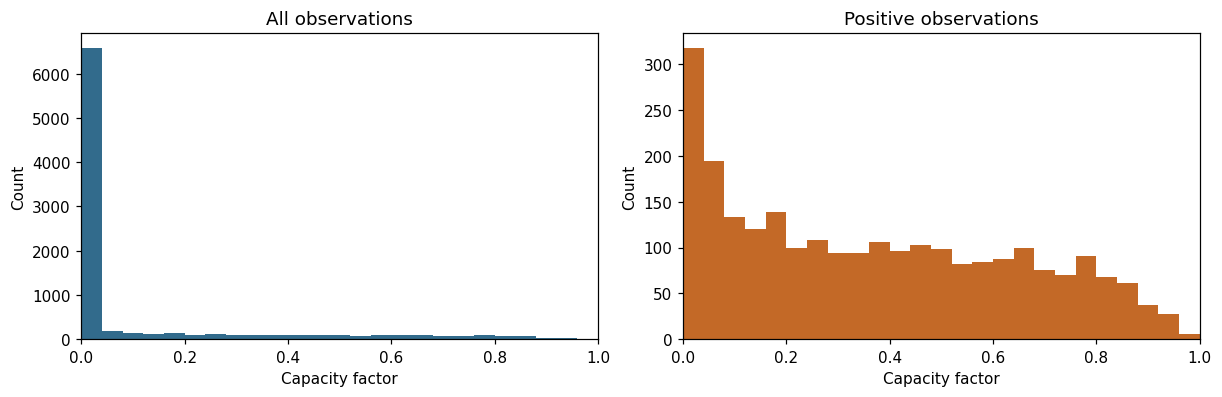

In [2]:
solar_fig, solar_axes = plt.subplots(1, 2, figsize=(11, 3.5), layout="constrained")
solar_axes[0].hist(solar_valid.dropna(), bins=25, range=(0, 1), color="#326b8c")
solar_axes[1].hist(solar_valid[solar_valid.gt(0)], bins=25, range=(0, 1), color="#c36927")
for solar_ax, solar_title in zip(solar_axes, ["All observations", "Positive observations"]):
    solar_ax.set(title=solar_title, xlabel="Capacity factor", ylabel="Count", xlim=(0, 1))
plt.show()

## Patterns in file order

The full series shows how values vary across the file. The first 168 observations provide a closer look at alternating runs of zero and positive values.

Autocorrelation at lag 24: 0.816


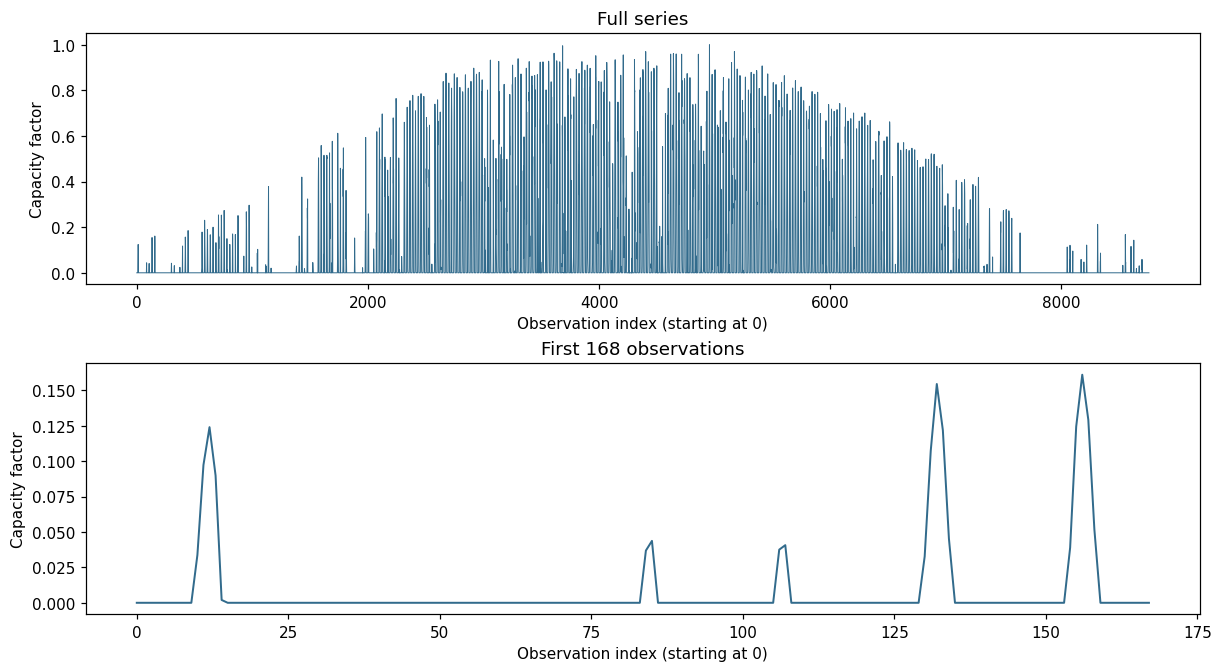

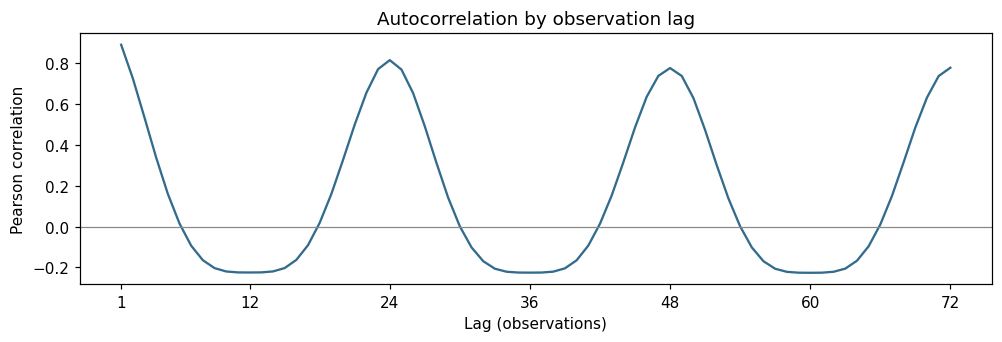

In [3]:
solar_fig, solar_axes = plt.subplots(2, 1, figsize=(11, 6), layout="constrained")
solar_axes[0].plot(solar_valid, linewidth=0.65, color="#326b8c")
solar_axes[1].plot(solar_valid.iloc[:168], linewidth=1.3, color="#326b8c")
for solar_ax, solar_title in zip(solar_axes, ["Full series", "First 168 observations"]):
    solar_ax.set(title=solar_title, xlabel="Observation index (starting at 0)", ylabel="Capacity factor")
plt.show()

solar_autocorrelation = pd.Series(
    {lag: solar_valid.autocorr(lag) for lag in range(1, 73)},
    name="Autocorrelation",
)
solar_fig, solar_ax = plt.subplots(figsize=(9, 3), layout="constrained")
solar_ax.plot(solar_autocorrelation, color="#326b8c")
solar_ax.set(title="Autocorrelation by observation lag", xlabel="Lag (observations)", ylabel="Pearson correlation")
solar_ax.set_xticks([1, 12, 24, 36, 48, 60, 72])
solar_ax.axhline(0, color="#888888", linewidth=0.8)
plt.show()
print(f"Autocorrelation at lag 24: {solar_autocorrelation.loc[24]:.3f}")

## Findings

- Zero capacity factor is common and is retained as an observed value. Repeated values alone cannot establish duplicate records because the file provides no record identifier.
- A lag of 24 observations has a correlation of 0.816. The recurring peaks suggest a repeating pattern in file order.
- At the documented hourly sampling interval, lag 24 corresponds to one day. Calendar labels below depend on the assumed start time.

## Distribution checks and calendar profiles

The boxplot and IQR screen use positive observations to avoid letting the large mass at zero dominate the thresholds. Flagged observations are descriptive and are retained. Period summaries use mean capacity factor, a unitless fraction.

Overall skewness: 2.149
Positive observations flagged by IQR: 0 of 2495
Highest daily means:
2021-05-31    0.3111
2021-06-19    0.3085
2021-07-06    0.2960
Lowest daily means (first three if tied):
2021-01-02    0.0
2021-01-03    0.0
2021-01-08    0.0
Peak average hour: 12:00
Highest average month: 8
Lowest average month: 12


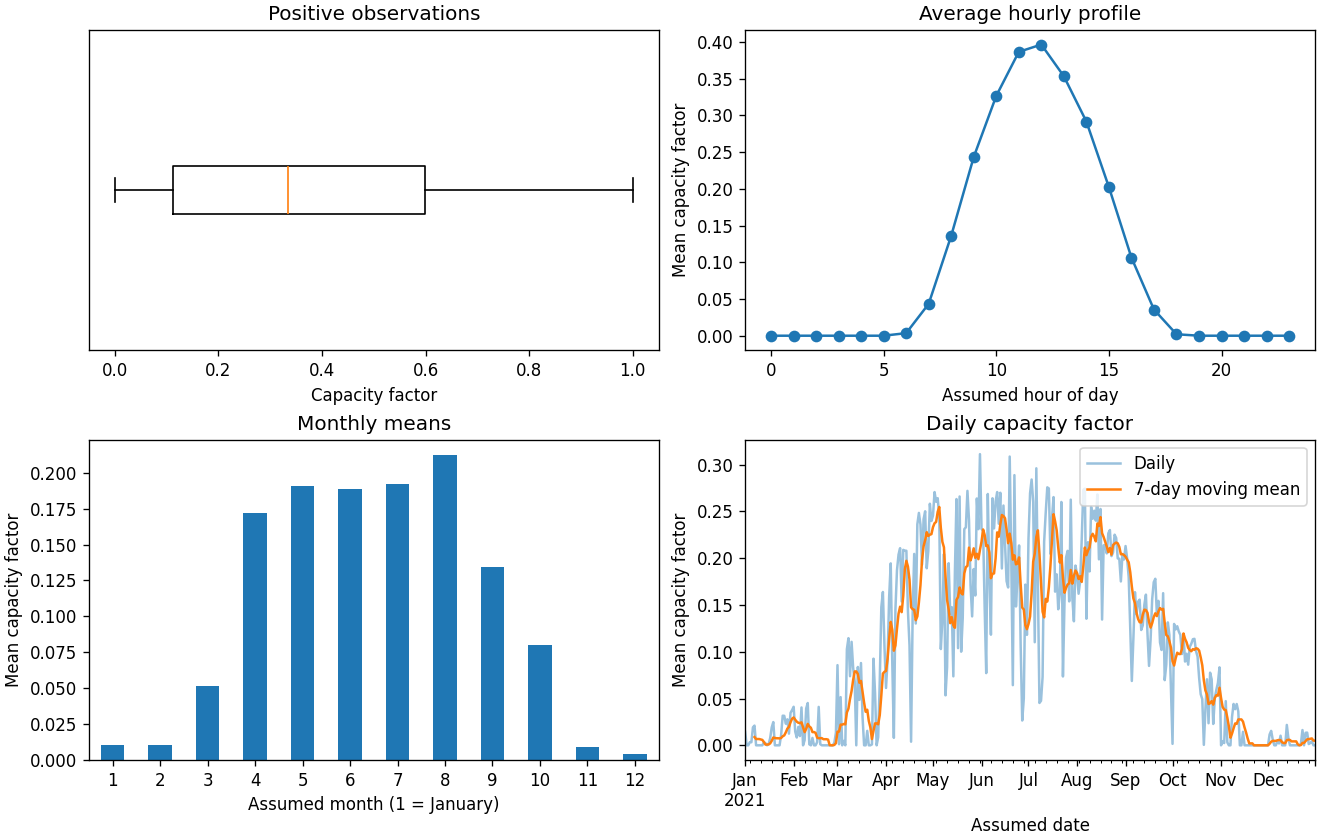

In [4]:
solar_positive = solar_valid[solar_valid.gt(0)]
solar_q1, solar_q3 = solar_positive.quantile([0.25, 0.75])
solar_iqr = solar_q3 - solar_q1
solar_flags = ~solar_positive.between(solar_q1 - 1.5 * solar_iqr, solar_q3 + 1.5 * solar_iqr)
print(f"Overall skewness: {solar_valid.skew():.3f}")
print(f"Positive observations flagged by IQR: {solar_flags.sum()} of {solar_positive.size}")

solar_hourly = solar_valid.set_axis(pd.date_range("2021-01-01", periods=len(solar_valid), freq="h"))
solar_hour_profile = solar_hourly.groupby(solar_hourly.index.hour).mean()
solar_month_profile = solar_hourly.groupby(solar_hourly.index.month).mean()
solar_daily = solar_hourly.resample("D").mean()
print("Highest daily means:")
print(solar_daily.nlargest(3).round(4).to_string())
print("Lowest daily means (first three if tied):")
print(solar_daily.nsmallest(3).round(4).to_string())
print(f"Peak average hour: {solar_hour_profile.idxmax():02d}:00")
print(f"Highest average month: {solar_month_profile.idxmax()}")
print(f"Lowest average month: {solar_month_profile.idxmin()}")

solar_fig, solar_axes = plt.subplots(2, 2, figsize=(11, 7), layout="constrained")
solar_axes[0, 0].boxplot(solar_positive, vert=False)
solar_axes[0, 0].set(title="Positive observations", xlabel="Capacity factor", yticks=[])
solar_hour_profile.plot(ax=solar_axes[0, 1], marker="o")
solar_axes[0, 1].set(title="Average hourly profile", xlabel="Assumed hour of day", ylabel="Mean capacity factor")
solar_month_profile.plot.bar(ax=solar_axes[1, 0], rot=0)
solar_axes[1, 0].set(title="Monthly means", xlabel="Assumed month (1 = January)", ylabel="Mean capacity factor")
solar_daily.plot(ax=solar_axes[1, 1], alpha=0.45, label="Daily")
solar_daily.rolling(7).mean().plot(ax=solar_axes[1, 1], label="7-day moving mean")
solar_axes[1, 1].set(title="Daily capacity factor", xlabel="Assumed date", ylabel="Mean capacity factor")
solar_axes[1, 1].legend()
plt.show()

The average hourly profile peaks at 12:00 under the assumed alignment. Month 8 has the highest mean and month 12 has the lowest. The rolling mean shows changes over the year while reducing day-to-day variation.

## 4.2 Data preparation

Each row represents the hour whose capacity factor is to be predicted. The 2021 hourly grid uses the start time assumed in the EDA above. The checks validate the constructed index. The raw CSV has no timestamps for independently checking gaps or duplicate hours.

Observed zeros are kept. Missing, nonnumeric and out-of-range values are excluded from training rows that require them. The positive-only IQR flag is diagnostic metadata based on the observed target. The model inputs are the cyclical hour and capacity factors from 1, 24 and 168 hours earlier. The first 168 observations lack full lag history, so the export starts on the eighth day. Use a chronological split for evaluation.

In [5]:
import numpy as np

solar_prepared = solar_hourly.rename("capacity_factor").to_frame()
solar_prepared.index.name = "data_hora"
assert len(solar_prepared) == 365 * 24
assert solar_prepared.index.is_unique and solar_prepared.index.is_monotonic_increasing
assert solar_prepared.index.to_series().diff().dropna().eq(pd.Timedelta(hours=1)).all()

solar_prepared["atipico"] = solar_flags.reindex(solar_valid.index, fill_value=False).to_numpy()
solar_angle = 2 * np.pi * solar_prepared.index.hour / 24
solar_prepared["hour_sin"] = np.sin(solar_angle)
solar_prepared["hour_cos"] = np.cos(solar_angle)
solar_features = ["hour_sin", "hour_cos"]

for solar_lag in (1, 24, 168):
    solar_column = f"capacity_factor_lag_{solar_lag}h"
    solar_prepared[solar_column] = solar_prepared["capacity_factor"].shift(solar_lag)
    solar_features.append(solar_column)

solar_export = solar_prepared.dropna(subset=["capacity_factor", *solar_features])
solar_root = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / solar_relative_path).is_file()),
    None,
)
solar_output_dir = solar_root / "dataset/final" if solar_root else Path.cwd()
solar_output_dir.mkdir(parents=True, exist_ok=True)
solar_output_path = solar_output_dir / "dados_solar_thermal_preparados.csv"
solar_export.to_csv(solar_output_path)

print(f"Input rows: {len(solar_prepared):,}")
print(f"Export rows: {len(solar_export):,}")
print(f"Rows excluded for incomplete target or lag history: {len(solar_prepared) - len(solar_export):,}")
print(f"Saved {solar_output_path.name}")
print("Model features:", ", ".join(solar_features))
print(solar_export.head(3).round(4).to_string())

Input rows: 8,760
Export rows: 8,592
Rows excluded for incomplete target or lag history: 168
Saved dados_solar_thermal_preparados.csv
Model features: hour_sin, hour_cos, capacity_factor_lag_1h, capacity_factor_lag_24h, capacity_factor_lag_168h
                     capacity_factor  atipico  hour_sin  hour_cos  capacity_factor_lag_1h  capacity_factor_lag_24h  capacity_factor_lag_168h
data_hora                                                                                                                                   
2021-01-08 00:00:00              0.0    False    0.0000    1.0000                     0.0                      0.0                       0.0
2021-01-08 01:00:00              0.0    False    0.2588    0.9659                     0.0                      0.0                       0.0
2021-01-08 02:00:00              0.0    False    0.5000    0.8660                     0.0                      0.0                       0.0
